# 💬 Análisis de sentimiento en español con RNN / LSTM / GRU

**Objetivo:** clasificar textos en español como **positivo**, **neutral** o **negativo** con redes recurrentes (TensorFlow/Keras).

**Contenido:** 1) Dataset · 2) EDA · 3) Limpieza · 4) División train/val/test · 5) Vectorización · 6) Modelos y experimentos ·
7) Gráficas · 8) Evaluación · 9) Predicciones · 10) Guardado del modelo.

> 💡 Activa GPU (opcional): *Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*.

## 0. Configuración

In [1]:
import os, re, json, random
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")
LABELS = ["positivo", "neutral", "negativo"]

# Todas las gráficas se guardan en reports/figuras/ para que queden en el repositorio
from pathlib import Path
FIG_DIR = Path("reports/figuras"); FIG_DIR.mkdir(parents=True, exist_ok=True)
def guardar(nombre):
    plt.savefig(FIG_DIR / f"{nombre}.png", dpi=130, bbox_inches="tight")
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | Keras: 3.13.2 | GPU: []


## 1. Selección y descripción del dataset

**multilingual-sentiments (config `spanish`)**, de Hugging Face (`tyqiangz/multilingual-sentiments`): textos en español
etiquetados con sentimiento **positivo, neutral o negativo** (licencia Apache 2.0).

- **Por qué es secuencial:** el sentimiento depende del orden y del contexto ("no está *mal*" ≠ "está *mal*").
- **Tipo de problema:** clasificación **multiclase** (3 clases) → salida `softmax` y `sparse_categorical_crossentropy`.
- Se unen los splits originales y se vuelve a dividir 70/15/15 de forma estratificada.

In [7]:
import os
import pandas as pd
import urllib.request
import json

# Consultamos la API oficial de Hugging Face para obtener las URLs reales y vigentes de los archivos Parquet exportados
print("Consultando la API de Hugging Face para obtener los archivos de datos...")
dataset_name = "tyqiangz/multilingual-sentiments"
config_name = "spanish"
api_url = f"https://datasets-server.huggingface.co/parquet?dataset={dataset_name}"

try:
    with urllib.request.urlopen(api_url) as response:
        data = json.loads(response.read().decode())

    # Filtramos las URLs correspondientes a la configuración de español ('spanish')
    parquet_files = [file_info for file_info in data["parquet_files"] if file_info["config"] == config_name]

    dfs = []
    for split in ["train", "validation", "test"]:
        # Buscamos la URL correspondiente a cada split
        split_files = [f["url"] for f in parquet_files if f["split"] == split]
        if split_files:
            print(f"Descargando split '{split}' de: {split_files[0]}")
            dfs.append(pd.read_parquet(split_files[0]))
        else:
            raise ValueError(f"No se encontró el split {split} en la API de Hugging Face")

    df = pd.concat(dfs, ignore_index=True)[["text", "label"]]
    df["etiqueta"] = df["label"].map(dict(enumerate(LABELS)))

    os.makedirs("data", exist_ok=True)
    df[["text", "label"]].to_csv("data/dataset.csv", index=False)  # Guarda una copia local
    print("\nForma final del dataset:", df.shape)

    # Comprobación rápida para verificar la consistencia de las etiquetas:
    for lab in LABELS:
        print(f"\n--- {lab} ---")
        for t in df.loc[df.etiqueta == lab, "text"].head(3):
            print(" •", t[:120])

except Exception as e:
    print(f"Ocurrió un error al obtener o procesar el dataset: {e}")

Consultando la API de Hugging Face para obtener los archivos de datos...
Descargando split 'train' de: https://huggingface.co/datasets/tyqiangz/multilingual-sentiments/resolve/refs%2Fconvert%2Fparquet/spanish/train/0000.parquet
Descargando split 'validation' de: https://huggingface.co/datasets/tyqiangz/multilingual-sentiments/resolve/refs%2Fconvert%2Fparquet/spanish/validation/0000.parquet
Descargando split 'test' de: https://huggingface.co/datasets/tyqiangz/multilingual-sentiments/resolve/refs%2Fconvert%2Fparquet/spanish/test/0000.parquet

Forma final del dataset: (3033, 3)

--- positivo ---
 • Esto de estar feliz mola
 • @user @user @user con una pequeña donación hará felices a miles de chicas que no tienen  #asociacionmariloli
 • @user aquí tienes a mi bae aka una egipcia preciosa que esta aprendiendo español. Os llevareis bien  @user

--- neutral ---
 • @user Por?  Tenía pensado verla después de la segunda de Daredevil
 • @user te recuerdo que soy una persona que tiene criterio, eq

## 2. Análisis exploratorio de datos (EDA)

Nulos:
 text        0
label       0
etiqueta    0
dtype: int64 

Duplicados: 0
etiqueta
negativo    1011
neutral     1011
positivo    1011
Name: count, dtype: int64 
 etiqueta
negativo    0.333
neutral     0.333
positivo    0.333
Name: proportion, dtype: float64


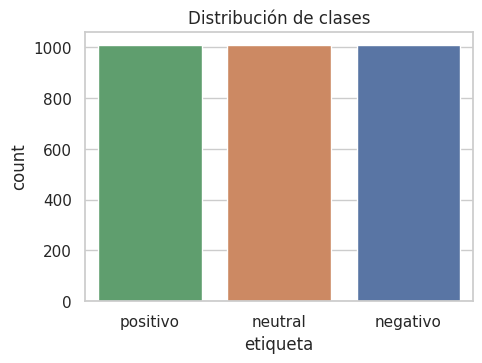

In [8]:
print("Nulos:\n", df.isna().sum(), "\n")
print("Duplicados:", df.duplicated(subset="text").sum())
print(df["etiqueta"].value_counts(), "\n", df["etiqueta"].value_counts(normalize=True).round(3))
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="etiqueta", order=LABELS, hue="etiqueta", legend=False, ax=ax)
ax.set_title("Distribución de clases"); guardar("01_distribucion_clases"); plt.show()

           count  mean  std  min   25%   50%   75%   max
etiqueta                                                
negativo  1011.0  16.2  6.4  5.0  11.0  16.0  21.0  33.0
neutral   1011.0  15.6  6.2  5.0  10.0  15.0  21.0  30.0
positivo  1011.0  15.0  5.8  5.0  11.0  15.0  19.0  30.0


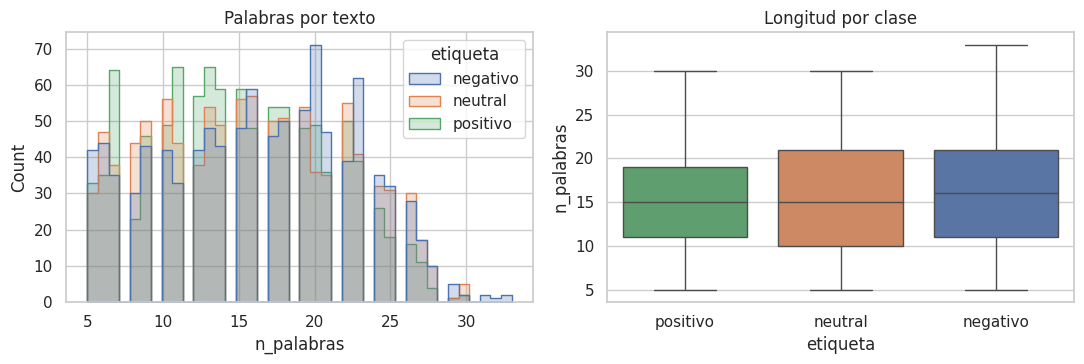

Percentil 95: 26


In [9]:
df["n_palabras"] = df["text"].str.split().str.len()
print(df.groupby("etiqueta")["n_palabras"].describe().round(1))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(data=df, x="n_palabras", hue="etiqueta", bins=40, element="step", ax=axes[0]); axes[0].set_title("Palabras por texto")
sns.boxplot(data=df, x="etiqueta", y="n_palabras", order=LABELS, hue="etiqueta", legend=False, ax=axes[1]); axes[1].set_title("Longitud por clase")
plt.tight_layout(); guardar("02_longitud_textos"); plt.show()
print("Percentil 95:", int(np.percentile(df["n_palabras"], 95)))

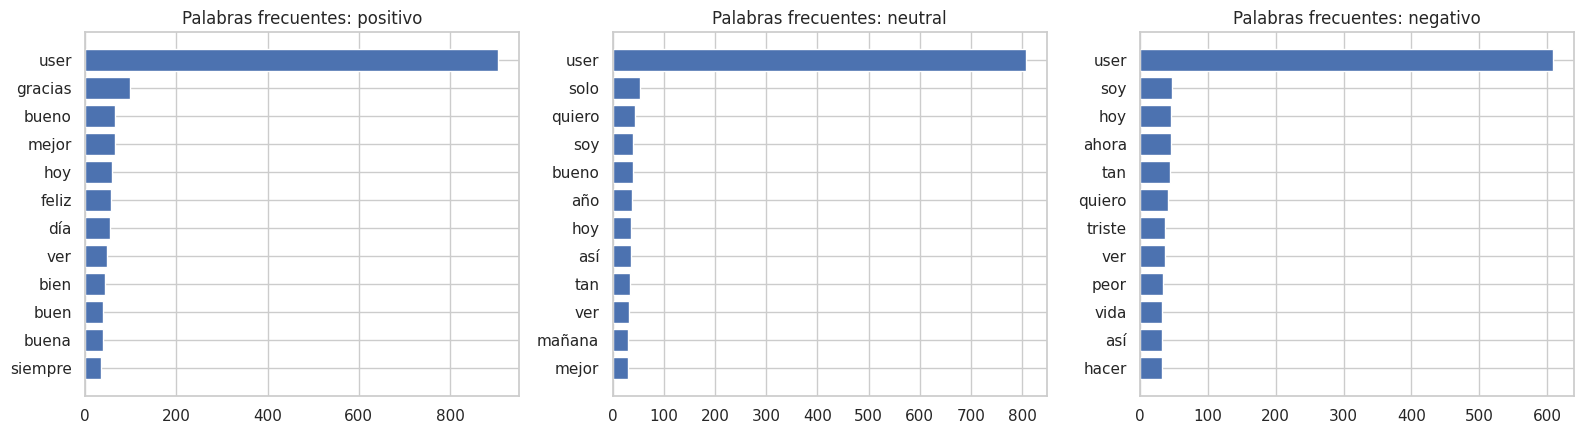

In [10]:
# Stopwords SOLO para el EDA (el modelo las conserva: "no", "muy", "nada" cambian el sentimiento)
STOP = set("de la que el en y a los se del las un por con no una su para es al lo como más pero sus le ya o este si porque esta entre cuando muy sin sobre también me hasta hay donde desde todo nos todos uno les ni otros ese eso ante esto antes qué unos yo otro otra tanto esa estos mucho nada poco algo mi mis tu te ha han he era fue son ser está están estoy tiene tengo q lo".split())
def top_words(texts, n=12):
    c = Counter()
    for t in texts: c.update(w for w in re.findall(r"[a-záéíóúñü]+", t.lower()) if w not in STOP and len(w) > 2)
    return c.most_common(n)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, lab in zip(axes, LABELS):
    w, c = zip(*top_words(df.loc[df.etiqueta == lab, "text"]))
    ax.barh(w[::-1], c[::-1]); ax.set_title(f"Palabras frecuentes: {lab}")
plt.tight_layout(); guardar("03_palabras_frecuentes"); plt.show()

## 3. Limpieza y preprocesamiento

- Eliminar duplicados y nulos.
- Minúsculas (se conservan tildes y ñ).
- URLs y @menciones → tokens genéricos; letras repetidas ("buenooooo" → "buenoo").
- **No** se eliminan stopwords. La puntuación (incluidos ¡ ¿) la elimina `TextVectorization`.

> `clean_text` es la misma función de `utils.py`, usada en `predict.py` y `app.py`.

In [11]:
URL_RE, MENTION_RE, REPEAT_RE = re.compile(r"(https?://\S+|www\.\S+)"), re.compile(r"@\w+"), re.compile(r"(.)\1{2,}")
def clean_text(t):
    t = str(t).lower()
    t = URL_RE.sub(" urltoken ", t); t = MENTION_RE.sub(" usuario ", t); t = REPEAT_RE.sub(r"\1\1", t)
    return re.sub(r"\s+", " ", t).strip()

df = df.dropna().drop_duplicates(subset="text").reset_index(drop=True)
df["clean"] = df["text"].apply(clean_text)
print("Tras limpiar:", df.shape)
df[["text", "clean"]].sample(5, random_state=SEED)

Tras limpiar: (3033, 5)


,text,clean
789,@user somos más felices sin ti,usuario somos más felices sin ti
257,@user que yo soy fiel tío,usuario que yo soy fiel tío
807,"@user ugh siii, de lo peor","usuario ugh sii, de lo peor"
2499,Se ha acabado el mes más bonito del año,se ha acabado el mes más bonito del año
1868,#FF a los geniales @user !!,#ff a los geniales usuario !!


## 4. División en entrenamiento, validación y prueba

70 / 15 / 15 **estratificada**, antes de construir el vocabulario (sin fuga de datos).

In [12]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
for n, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"{n:5}: {len(d):5} |", d["etiqueta"].value_counts(normalize=True).round(3).to_dict())

Train:  2123 | {'neutral': 0.333, 'positivo': 0.333, 'negativo': 0.333}
Val  :   455 | {'neutral': 0.334, 'negativo': 0.334, 'positivo': 0.332}
Test :   455 | {'negativo': 0.334, 'positivo': 0.334, 'neutral': 0.332}


## 5. Vectorización

`TextVectorization` se adapta **solo con entrenamiento** y va **dentro del modelo**, así el modelo guardado recibe texto.

In [13]:
VOCAB_SIZE = 10000
MAX_LEN = int(np.percentile([len(t.split()) for t in train_df["clean"]], 95))
vectorizer = layers.TextVectorization(max_tokens=VOCAB_SIZE, output_mode="int", output_sequence_length=MAX_LEN,
                                      standardize="lower_and_strip_punctuation")
vectorizer.adapt(np.array(train_df["clean"], dtype=str))
print("MAX_LEN =", MAX_LEN, "| vocabulario =", vectorizer.vocabulary_size())
print("Primeras palabras:", vectorizer.get_vocabulary()[:15])
ej = train_df["clean"].iloc[0]; print("\nTexto :", ej); print("Tokens:", vectorizer(tf.constant([ej]))[0].numpy())

BATCH = 32
def make_ds(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((np.array(X, dtype=str), np.array(y, dtype="int32")))
    if shuffle: ds = ds.shuffle(len(X), seed=SEED)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)
train_ds, val_ds, test_ds = make_ds(train_df.clean, train_df.label, True), make_ds(val_df.clean, val_df.label), make_ds(test_df.clean, test_df.label)

MAX_LEN = 26 | vocabulario = 7058
Primeras palabras: ['', '[UNK]', np.str_('usuario'), np.str_('que'), np.str_('de'), np.str_('y'), np.str_('a'), np.str_('no'), np.str_('la'), np.str_('me'), np.str_('en'), np.str_('el'), np.str_('es'), np.str_('lo'), np.str_('un')]

Texto : y eso es triste la vdd. por vosotros, no por mi
Tokens: [   5   48   12  109    8 1307   15  717    7   15   17    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0]


## 6. Construcción y entrenamiento de la red neuronal

`TextVectorization → Embedding → [SimpleRNN | LSTM | GRU | BiLSTM] → Dropout → Dense(32) → Dropout → Dense(3, softmax)`

- **Pérdida:** `sparse_categorical_crossentropy` (etiquetas enteras, 3 clases).
- **Regularización:** Dropout 0.4 + `EarlyStopping` (patience=3) + `ModelCheckpoint`.
- **Desbalance:** `class_weight` balanceado.
- Se comparan 4 arquitecturas y se elige la mejor por **F1 macro en validación** (nunca en test).

In [14]:
EMBED_DIM, UNITS, DROPOUT = 64, 64, 0.4
def build_model(kind):
    inp = keras.Input(shape=(), dtype=tf.string, name="texto")
    x = layers.Embedding(vectorizer.vocabulary_size(), EMBED_DIM, mask_zero=True)(vectorizer(inp))
    x = {"SimpleRNN": lambda: layers.SimpleRNN(UNITS), "LSTM": lambda: layers.LSTM(UNITS), "GRU": lambda: layers.GRU(UNITS),
         "BiLSTM": lambda: layers.Bidirectional(layers.LSTM(UNITS))}[kind]()(x)
    x = layers.Dropout(DROPOUT)(x); x = layers.Dense(32, activation="relu")(x); x = layers.Dropout(DROPOUT)(x)
    out = layers.Dense(len(LABELS), activation="softmax", name="probabilidades")(x)
    m = keras.Model(inp, out, name=f"sentimiento_{kind.lower()}")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

build_model("BiLSTM").summary()
w = compute_class_weight("balanced", classes=np.arange(3), y=train_df["label"].values)
CLASS_WEIGHT = {i: float(v) for i, v in enumerate(w)}; print("class_weight:", CLASS_WEIGHT)

Model: "sentimiento_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ texto (InputLayer)  │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 26)        │          0 │ texto[0][0]       │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 26, 64)    │    451,712 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 26)        │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     66,048 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      4,128 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ probabilidades      │ (None, 3)         │         99 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 521,987 (1.99 MB)

 Trainable params: 521,987 (1.99 MB)

 Non-trainable params: 0 (0.00 B)

class_weight: {0: 0.9995291902071564, 1: 0.9995291902071564, 2: 1.000942951438001}


In [15]:
os.makedirs("modelo", exist_ok=True)
modelos, historias, resumen = {}, {}, []
yv = val_df["label"].values
for nombre in ["SimpleRNN", "LSTM", "GRU", "BiLSTM"]:
    print(f"\n===== Entrenando {nombre} =====")
    tf.keras.utils.set_random_seed(SEED)
    m = build_model(nombre)
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
          keras.callbacks.ModelCheckpoint(f"modelo/ckpt_{nombre}.keras", monitor="val_loss", save_best_only=True)]
    h = m.fit(train_ds, validation_data=val_ds, epochs=25, class_weight=CLASS_WEIGHT, callbacks=cb, verbose=2)
    pv = m.predict(val_ds, verbose=0); yp = pv.argmax(1)
    modelos[nombre], historias[nombre] = m, h
    pd.DataFrame(h.history).to_csv(f"reports/historial_{nombre}.csv", index_label="época")
    resumen.append({"modelo": nombre, "épocas": len(h.history["loss"]), "val_accuracy": accuracy_score(yv, yp),
                    "val_f1_macro": f1_score(yv, yp, average="macro"), "val_auc_ovr": roc_auc_score(yv, pv, multi_class="ovr")})
tabla = pd.DataFrame(resumen).set_index("modelo").round(4); tabla


===== Entrenando SimpleRNN =====
Epoch 1/25
67/67 - 2s - 36ms/step - accuracy: 0.3189 - loss: 1.1082 - val_accuracy: 0.3626 - val_loss: 1.0994
Epoch 2/25
67/67 - 1s - 9ms/step - accuracy: 0.4875 - loss: 1.0378 - val_accuracy: 0.4066 - val_loss: 1.0998
Epoch 3/25
67/67 - 1s - 10ms/step - accuracy: 0.6764 - loss: 0.7973 - val_accuracy: 0.3692 - val_loss: 1.2488
Epoch 4/25
67/67 - 1s - 9ms/step - accuracy: 0.8865 - loss: 0.3517 - val_accuracy: 0.3868 - val_loss: 1.5849

===== Entrenando LSTM =====
Epoch 1/25
67/67 - 4s - 53ms/step - accuracy: 0.3255 - loss: 1.0987 - val_accuracy: 0.3802 - val_loss: 1.0968
Epoch 2/25
67/67 - 1s - 16ms/step - accuracy: 0.4885 - loss: 1.0569 - val_accuracy: 0.4923 - val_loss: 1.0434
Epoch 3/25
67/67 - 1s - 17ms/step - accuracy: 0.6764 - loss: 0.7779 - val_accuracy: 0.4769 - val_loss: 1.1443
Epoch 4/25
67/67 - 1s - 14ms/step - accuracy: 0.8724 - loss: 0.3926 - val_accuracy: 0.4791 - val_loss: 1.5820
Epoch 5/25
67/67 - 1s - 19ms/step - accuracy: 0.9585 - loss

,épocas,val_accuracy,val_f1_macro,val_auc_ovr
modelo,,,,
SimpleRNN,4,0.3626,0.3346,0.5126
LSTM,5,0.4923,0.4908,0.6463
GRU,5,0.4593,0.4533,0.6476
BiLSTM,5,0.4857,0.4712,0.6784


## 7. Gráficas del entrenamiento

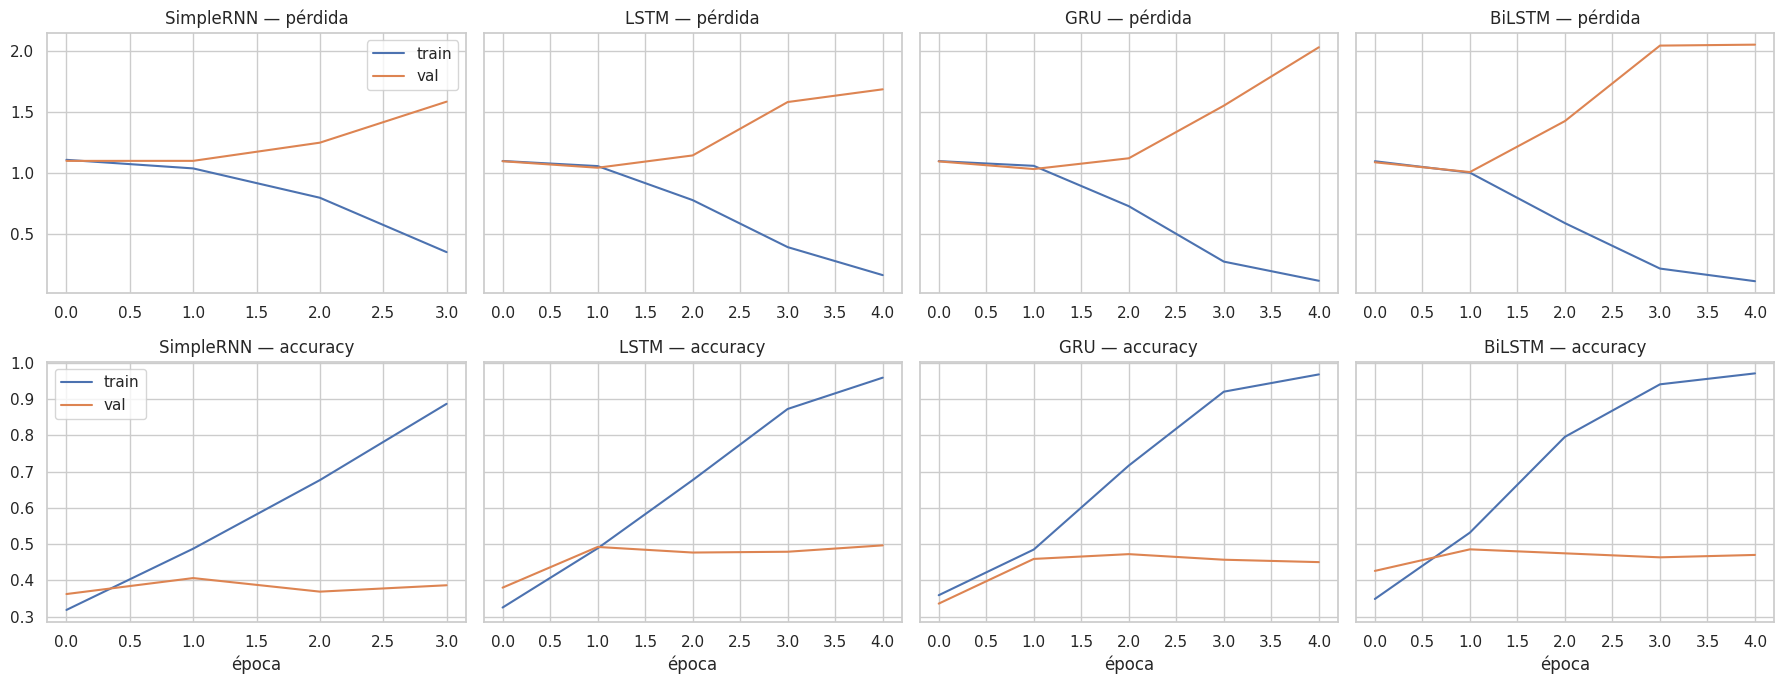

✅ Mejor modelo por F1 macro en validación: LSTM


In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey="row")
for j, (n, h) in enumerate(historias.items()):
    axes[0, j].plot(h.history["loss"], label="train"); axes[0, j].plot(h.history["val_loss"], label="val"); axes[0, j].set_title(f"{n} — pérdida")
    axes[1, j].plot(h.history["accuracy"], label="train"); axes[1, j].plot(h.history["val_accuracy"], label="val"); axes[1, j].set_title(f"{n} — accuracy")
    axes[1, j].set_xlabel("época")
axes[0, 0].legend(); axes[1, 0].legend(); plt.tight_layout(); guardar("04_curvas_comparacion_modelos"); plt.savefig("reports/curvas_entrenamiento.png", dpi=130, bbox_inches="tight"); plt.show()
mejor = tabla["val_f1_macro"].idxmax(); print(f"✅ Mejor modelo por F1 macro en validación: {mejor}")

Si la pérdida de validación sube mientras la de entrenamiento baja, hay sobreajuste; `EarlyStopping` restaura los mejores pesos. Compara la estabilidad de SimpleRNN frente a LSTM/GRU (el gradiente se desvanece más en secuencias largas).

## 8. Evaluación en el conjunto de prueba

              precision    recall  f1-score   support

    positivo     0.6078    0.4079    0.4882       152
     neutral     0.4264    0.5563    0.4828       151
    negativo     0.4679    0.4803    0.4740       152

    accuracy                         0.4813       455
   macro avg     0.5007    0.4815    0.4817       455
weighted avg     0.5009    0.4813    0.4817       455

ROC-AUC OvR: 0.6625


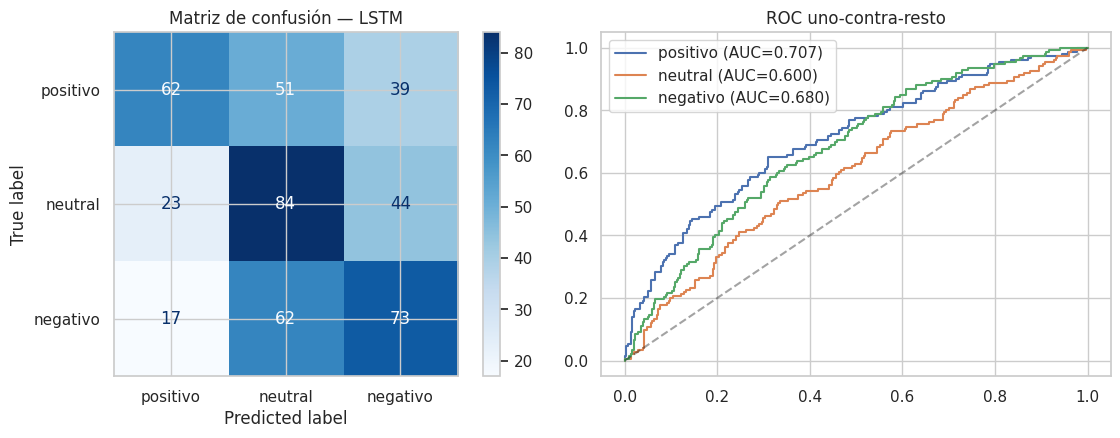

In [17]:
best = modelos[mejor]; y_test = test_df["label"].values
probs = best.predict(test_ds, verbose=0); preds = probs.argmax(1)
metrics = {"modelo": mejor, "accuracy": accuracy_score(y_test, preds),
           "precision_macro": precision_score(y_test, preds, average="macro"), "recall_macro": recall_score(y_test, preds, average="macro"),
           "f1_macro": f1_score(y_test, preds, average="macro"), "f1_weighted": f1_score(y_test, preds, average="weighted"),
           "roc_auc_ovr": roc_auc_score(y_test, probs, multi_class="ovr"), "confusion_matrix": confusion_matrix(y_test, preds).tolist(), "n_test": int(len(y_test))}
print(classification_report(y_test, preds, target_names=LABELS, digits=4)); print("ROC-AUC OvR:", round(metrics["roc_auc_ovr"], 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, preds, display_labels=LABELS, cmap="Blues", ax=axes[0]); axes[0].set_title(f"Matriz de confusión — {mejor}")
yb = label_binarize(y_test, classes=[0, 1, 2])
for i, lab in enumerate(LABELS):
    fpr, tpr, _ = roc_curve(yb[:, i], probs[:, i]); axes[1].plot(fpr, tpr, label=f"{lab} (AUC={roc_auc_score(yb[:, i], probs[:, i]):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4); axes[1].legend(); axes[1].set_title("ROC uno-contra-resto"); plt.tight_layout(); guardar("05_matriz_confusion_y_roc"); plt.savefig("reports/matriz_confusion.png", dpi=130, bbox_inches="tight"); plt.show()

**Interpretación:** en sentimiento, la clase *neutral* suele ser la más difícil (se confunde con las otras dos). Revisa la matriz de confusión y el recall por clase, no solo la accuracy.

## 9. Predicciones de prueba (≥ 10)

In [18]:
res = test_df.copy(); res["predicción"] = [LABELS[i] for i in preds]; res["confianza"] = probs.max(1); res["correcta"] = res["predicción"] == res["etiqueta"]
muestra = pd.concat([g.sample(4, random_state=SEED) for _, g in res.groupby("etiqueta")])[["text", "etiqueta", "predicción", "confianza", "correcta"]].reset_index(drop=True)
muestra["text"] = muestra["text"].str.slice(0, 85); pd.set_option("display.max_colwidth", 95); muestra.round(3)

,text,etiqueta,predicción,confianza,correcta
0,No hay mayores problemas dice vocero Lewin Mejía sobre amago de incendio... es un cen,negativo,negativo,0.431,True
1,"@user y mi pobre hija tragando, no es justo",negativo,negativo,0.397,True
2,"Llevo dos claras de huevo batidas en mis raíces para que me crezca el pelo, como no f",negativo,negativo,0.443,True
3,"gritaba muchísimo, mordió a mi hermana y lo tenían que agarrar pfff de verdad lo he p",negativo,negativo,0.424,True
4,Quiero como tener carro para hacer todo rápido,neutral,neutral,0.358,True
5,@user @user jajaja ya somos un pollito! La próxima semana? a ver que dice @user,neutral,neutral,0.426,True
6,"Yo veía #VBQ por Dani y Pamela, normal que maten a mi otp. Siempre me pasa jajhshdga",neutral,neutral,0.422,True
7,"Queda claro que yo solo vivo para viajar~ No necesito casas ni propiedades, solo nece",neutral,negativo,0.491,False
8,que madre mas graciosa tengo,positivo,positivo,0.353,True
9,"@user Gracias ya me pasó una vez y los antibióticos fueron milagrosos, estoy deseand",positivo,neutral,0.374,False


In [19]:
err = res[~res["correcta"]][["text", "etiqueta", "predicción", "confianza"]].round(3)
err.to_csv("reports/errores_test.csv", index=False)
print(f"Errores: {len(err)} de {len(res)}"); err.head(10)

Errores: 236 de 455


,text,etiqueta,predicción,confianza
2058,@user @user más bien una piedra pintada,negativo,positivo,0.471
1911,@user @user puf no veas pobre chaval y donde lo han metido con toda esa gente,negativo,neutral,0.428
2770,"@user jo,es que es mortal",neutral,positivo,0.386
2245,@user eres muy peque para eso,neutral,positivo,0.489
98,"@user Que guapísimo , dejaron mendizorroza, pero San mames ... de los + guapos del MUNDO¡¡ ...",positivo,neutral,0.404
1661,@user @user @user Sí! Yo creo que vamos a acabar muuuuuuuuy contentas,positivo,neutral,0.463
2461,"@user Mira q me gustaría, Juan, hablar contigo con emoticonos, pero está visto que ntros mó...",neutral,negativo,0.433
2189,@user pero yo te kiero,positivo,neutral,0.410
303,@user ni tu como soportas el calor sevillano hija mía,negativo,neutral,0.425
1126,En cuanto se vaya fabi no pienso salir de mi casa en por lo menos tres días,neutral,negativo,0.400


## 10. Guardado del modelo

Se guarda en formato `.keras` con la capa `TextVectorization` incluida, y se verifica que al recargarlo da las mismas predicciones.

In [20]:
os.makedirs("reports", exist_ok=True)
best.save("modelo/modelo_sentimiento.keras")
config = {"model": mejor.lower(), "max_len": MAX_LEN, "vocab_size": VOCAB_SIZE, "vocab_real": int(vectorizer.vocabulary_size()),
          "embed_dim": EMBED_DIM, "units": UNITS, "dropout": DROPOUT, "batch_size": BATCH, "seed": SEED, "labels": LABELS}
json.dump(config, open("modelo/config.json", "w"), indent=2); json.dump(metrics, open("reports/metrics.json", "w"), indent=2)
tabla.to_csv("reports/comparacion_modelos.csv"); muestra.to_csv("reports/predicciones_test.csv", index=False)

reloaded = keras.models.load_model("modelo/modelo_sentimiento.keras")
frases = ["Me encantó, llegó rápido y la calidad es excelente", "Es un producto normal, cumple lo básico", "Pésimo, llegó roto y nadie respondió mis reclamos"]
for f, p in zip(frases, reloaded.predict(tf.constant([clean_text(f) for f in frases]), verbose=0)):
    print(f"{LABELS[p.argmax()]:9} ({p.max():.2f}) | {f}")
print("\nDiferencia máx. original vs recargado:", float(np.abs(best.predict(test_ds, verbose=0) - reloaded.predict(test_ds, verbose=0)).max()))

positivo  (0.38) | Me encantó, llegó rápido y la calidad es excelente
positivo  (0.34) | Es un producto normal, cumple lo básico
negativo  (0.38) | Pésimo, llegó roto y nadie respondió mis reclamos

Diferencia máx. original vs recargado: 0.0


In [21]:
import shutil
for f in os.listdir("modelo"):
    if f.startswith("ckpt_"): os.remove(os.path.join("modelo", f))

# Versiones exactas del entorno (sirven para fijar requirements.txt)
import platform, zipfile
from importlib import metadata
lineas = [f"# Entorno de ejecución en Colab ({pd.Timestamp.now():%Y-%m-%d})", f"python=={platform.python_version()}",
          f"gpu={[g.name for g in tf.config.list_physical_devices('GPU')]}"]
for pkg in ["tensorflow", "keras", "numpy", "pandas", "scikit-learn", "matplotlib", "seaborn", "pyarrow"]:
    try: lineas.append(f"{pkg}=={metadata.version(pkg)}")
    except metadata.PackageNotFoundError: pass
Path("reports/versiones_colab.txt").write_text("\n".join(lineas) + "\n"); print("\n".join(lineas))

# Un solo .zip con todo lo generado (modelo, reportes, gráficas y dataset)
with zipfile.ZipFile("resultados_colab.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for carpeta in ["modelo", "reports"]:
        for f in Path(carpeta).rglob("*"):
            if f.is_file(): z.write(f)
    z.write("data/dataset.csv")
print("\nArchivos incluidos en resultados_colab.zip:", len(zipfile.ZipFile("resultados_colab.zip").namelist()))
try:
    from google.colab import files
    files.download("resultados_colab.zip")
except ImportError:
    print("Fuera de Colab: resultados_colab.zip quedó en la carpeta actual")

# Entorno de ejecución en Colab (2026-10-14)
python==3.13.16
gpu=[]
tensorflow==2.21.0
keras==3.13.2
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
pyarrow==23.0.1

Archivos incluidos en resultados_colab.zip: 19


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusiones

- Indica qué arquitectura ganó y por cuánto (tabla de la sección 6).
- Analiza qué clase se confunde más (probablemente *neutral*) y los errores de la sección 9.
- Limitaciones: dataset de reseñas (puede rendir peor con otros dominios), ironía y sarcasmo.
- Mejoras: embeddings preentrenados en español, más datos, o un Transformer (BETO).

## 12. Qué subir al repositorio (importante)

Todo lo hecho en este notebook debe quedar en el repositorio:

1. **Este notebook con sus resultados.** Con todas las celdas ejecutadas (*Entorno de ejecución → Reiniciar y ejecutar todo*), ve a *Archivo → Descargar → Descargar .ipynb* y reemplaza `notebook_experimentacion.ipynb` del repositorio. Así se conservan las salidas, tablas y gráficas.
2. **`resultados_colab.zip`** (se descargó solo en la celda anterior): descomprímelo en la raíz del repositorio. Contiene `modelo/`, `reports/` (métricas, historiales, versiones del entorno y `figuras/` con todas las gráficas) y `data/dataset.csv`.
3. Ejecuta `python verificar_entrega.py` para comprobar que no falta nada y luego `git add .`, `git commit` y `git push`.